In [1]:
import numpy as np
import pandas as pd
from catboost import CatBoostRegressor, Pool
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt
import seaborn as sns
import os

In [2]:
# Настройка визуализации
plt.style.use('seaborn-v0_8')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 12

np.random.seed(42)

In [3]:
def generate_training_data(n_samples=10000):

    prices = np.random.uniform(0, 5000, n_samples)

    a_coef = -0.00000796
    b_coef = 0.0434
    c_coef = 2.0
    
    fee_percent = a_coef * prices**2 + b_coef * prices + c_coef
    
    noise = np.random.normal(0, 0.5, n_samples)
    fee_percent = fee_percent + noise
    
    fee_percent = np.clip(fee_percent, 2.0, 20.0)
    
    exchanges = ['MOEX', 'NYSE', 'LSE', 'NASDAQ', 'BINANCE']
    exchange_labels = np.random.choice(exchanges, n_samples)
    
    exchange_adjustment = {
        'MOEX': 0.0,
        'NYSE': 0.5,
        'LSE': 0.3,
        'NASDAQ': 0.7,
        'BINANCE': -0.3
    }
    fee_percent = fee_percent + np.array([exchange_adjustment[e] for e in exchange_labels])
    fee_percent = np.clip(fee_percent, 2.0, 20.0)
    
    days_of_year = np.random.randint(1, 366, n_samples)
    dates = pd.to_datetime('2025-01-01') + pd.to_timedelta(days_of_year, unit='D')
    day_month = dates.strftime('%d-%m')
    
    df = pd.DataFrame({
        'class_birzhi': exchange_labels,
        'цена': prices,
        'timestamp_дата': day_month,
        'комиссия_процент': fee_percent
    })
    
    return df

In [4]:
print("Генерация обучающих данных\n")
df = generate_training_data(n_samples=10000)
print(f"\nКоличество: {len(df):,}")
print(df['цена'].describe())
print(df['комиссия_процент'].describe())

Генерация обучающих данных


Количество: 10,000
count    10000.000000
mean      2470.797788
std       1438.150633
min          0.058174
25%       1231.644345
50%       2462.643087
75%       3700.031741
max       4998.588366
Name: цена, dtype: float64
count    10000.000000
mean        19.167160
std          2.864545
min          2.000000
25%         19.700000
50%         20.000000
75%         20.000000
max         20.000000
Name: комиссия_процент, dtype: float64


/tmp/ipykernel_844375/3815536167.py:22: UserWarning: Glyph 8381 (\N{RUBLE SIGN}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_844375/3815536167.py:23: UserWarning: Glyph 8381 (\N{RUBLE SIGN}) missing from font(s) Liberation Sans.
  plt.savefig('output/commission_distribution.png', dpi=150, bbox_inches='tight')
/home/doctorstone/Документы/uran-235/.venv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 8381 (\N{RUBLE SIGN}) missing from font(s) Liberation Sans.
  fig.canvas.print_figure(bytes_io, **kw)


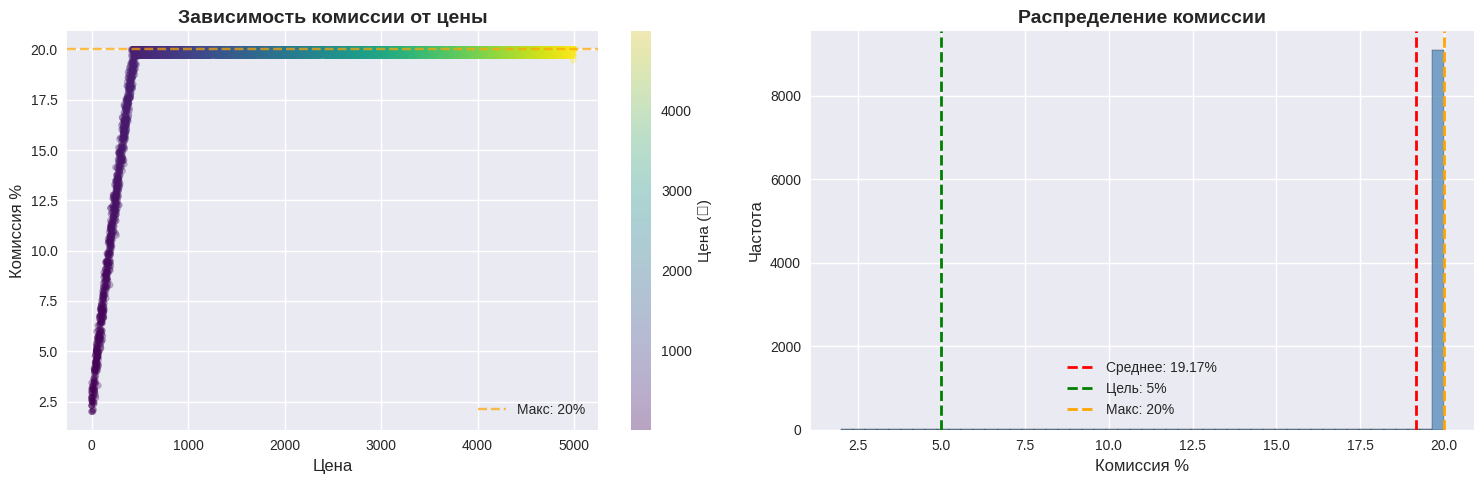

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

scatter = axes[0].scatter(df['цена'], df['комиссия_процент'], 
                         alpha=0.3, c=df['цена'], cmap='viridis', s=20)
axes[0].set_xlabel('Цена', fontsize=12)
axes[0].set_ylabel('Комиссия %', fontsize=12)
axes[0].set_title('Зависимость комиссии от цены', fontsize=14, fontweight='bold')
axes[0].axhline(y=20, color='orange', linestyle='--', alpha=0.7, label='Макс: 20%')
axes[0].legend()
plt.colorbar(scatter, ax=axes[0], label='Цена (₽)')

axes[1].hist(df['комиссия_процент'], bins=50, edgecolor='black', alpha=0.7, color='steelblue')
axes[1].axvline(x=df['комиссия_процент'].mean(), color='red', linestyle='--', 
                linewidth=2, label=f'Среднее: {df["комиссия_процент"].mean():.2f}%')
axes[1].axvline(x=5, color='green', linestyle='--', linewidth=2, label='Цель: 5%')
axes[1].axvline(x=20, color='orange', linestyle='--', linewidth=2, label='Макс: 20%')
axes[1].set_xlabel('Комиссия %', fontsize=12)
axes[1].set_ylabel('Частота', fontsize=12)
axes[1].set_title('Распределение комиссии', fontsize=14, fontweight='bold')
axes[1].legend()

plt.tight_layout()
plt.savefig('output/commission_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

In [6]:
display(df.head(10))

,class_birzhi,цена,timestamp_дата,комиссия_процент
0,NASDAQ,1872.700594,17-01,20.000000
1,NYSE,4753.571532,17-03,20.000000
2,NASDAQ,3659.969709,18-09,20.000000
3,MOEX,2993.292421,28-12,20.000000
4,BINANCE,780.093202,05-01,19.700000
5,MOEX,779.972602,09-09,20.000000
6,LSE,290.418061,27-03,14.275574
7,NYSE,4330.880729,05-03,20.000000
8,MOEX,3005.575059,11-04,20.000000
9,MOEX,3540.362889,19-11,20.000000


In [7]:
os.makedirs('output', exist_ok=True)
df.to_csv('output/training_data.csv', index=False)
print(f"\nДанные сохранены в 'output/training_data.csv'")


Данные сохранены в 'output/training_data.csv'


In [8]:
X = df.drop('комиссия_процент', axis=1)
y = df['комиссия_процент']

In [9]:
cat_features = ['class_birzhi', 'timestamp_дата']

print(f"Признаки: {list(X.columns)}")
print(f"Категориальные признаки: {cat_features}")
print(f"Целевая переменная: 'комиссия_процент'")

Признаки: ['class_birzhi', 'цена', 'timestamp_дата']
Категориальные признаки: ['class_birzhi', 'timestamp_дата']
Целевая переменная: 'комиссия_процент'


In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"\nРазмер обучающей выборки: {len(X_train):,}")
print(f"Размер тестовой выборки: {len(X_test):,}")


Размер обучающей выборки: 8,000
Размер тестовой выборки: 2,000


In [11]:
model = CatBoostRegressor(
    iterations=1000,
    depth=6,
    learning_rate=0.1,
    loss_function='MAE',
    cat_features=cat_features,
    verbose=100,
    random_seed=42,
    task_type="CPU",
    early_stopping_rounds=50
)

In [12]:
model.fit(
    X_train, y_train,
    eval_set=(X_test, y_test),
    use_best_model=True
)

0:	learn: 0.7549345	test: 0.7709173	best: 0.7709173 (0)	total: 51.2ms	remaining: 51.1s
100:	learn: 0.0496472	test: 0.0479001	best: 0.0479001 (100)	total: 619ms	remaining: 5.51s
200:	learn: 0.0434850	test: 0.0434595	best: 0.0434595 (200)	total: 1.2s	remaining: 4.78s
300:	learn: 0.0401538	test: 0.0422582	best: 0.0422102 (276)	total: 1.76s	remaining: 4.1s
Stopped by overfitting detector  (50 iterations wait)

bestTest = 0.04210361248
bestIteration = 348

Shrink model to first 349 iterations.


CatBoostRegressor(cat_features=['class_birzhi', 'timestamp_дата'], depth=6, early_stopping_rounds=50, iterations=1000, learning_rate=0.1, loss_function='MAE', random_seed=42, task_type='CPU', verbose=100)

In [13]:
y_pred = model.predict(X_test)

In [15]:
mae = mean_absolute_error(y_test, y_pred)
rmse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("\nМЕТРИКИ")
print(f"MAE (Средняя абсолютная ошибка): {mae:.4f}%")
print(f"RMSE (Среднеквадратичная ошибка): {rmse:.4f}%")
print(f"R^2 (Коэффициент детерминации): {r2:.4f}")


МЕТРИКИ
MAE (Средняя абсолютная ошибка): 0.0421%
RMSE (Среднеквадратичная ошибка): 0.0278%
R^2 (Коэффициент детерминации): 0.9967


In [16]:
errors = y_test - y_pred
axes[1].hist(errors, bins=50, edgecolor='black', alpha=0.7, color='coral')
axes[1].axvline(x=0, color='blue', linestyle='--', linewidth=2, label='Нулевая ошибка')
axes[1].axvline(x=mae, color='green', linestyle='--', linewidth=2, label=f'MAE: {mae:.2f}%')
axes[1].axvline(x=-mae, color='green', linestyle='--', linewidth=2)
axes[1].set_xlabel('Ошибка (Факт - Предсказание)', fontsize=12)
axes[1].set_ylabel('Частота', fontsize=12)
axes[1].set_title('Распределение ошибок предсказания', fontsize=14, fontweight='bold')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('output/model_predictions.png', dpi=150, bbox_inches='tight')
plt.show()

<Figure size 1200x600 with 0 Axes>

       feature  importance
          цена   96.077775
  class_birzhi    3.689281
timestamp_дата    0.232945


/tmp/ipykernel_844375/3887530475.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=importance_df, x='importance', y='feature', palette='viridis')


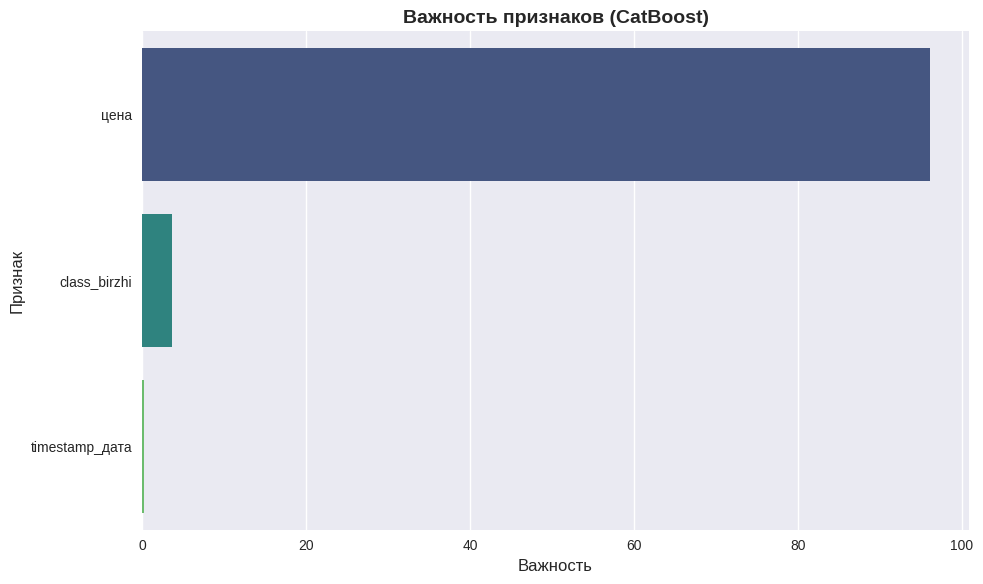

In [17]:
feature_importance = model.get_feature_importance()
feature_names = X.columns.tolist()

importance_df = pd.DataFrame({
    'feature': feature_names,
    'importance': feature_importance
}).sort_values('importance', ascending=False)

print(importance_df.to_string(index=False))

plt.figure(figsize=(10, 6))
sns.barplot(data=importance_df, x='importance', y='feature', palette='viridis')
plt.xlabel('Важность', fontsize=12)
plt.ylabel('Признак', fontsize=12)
plt.title('Важность признаков (CatBoost)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('output/feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

In [18]:
model.save_model('output/catboost_commission_model.cbm')
print("\nМодель сохранена в 'output/catboost_commission_model.cbm'")


Модель сохранена в 'output/catboost_commission_model.cbm'


In [19]:
metadata = {
    'cat_features': cat_features,
    'feature_names': list(X.columns),
    'target': 'комиссия_процент',
    'metrics': {
        'MAE': mae,
        'RMSE': rmse,
        'R2': r2
    }
}
metadata_df = pd.DataFrame([metadata])
metadata_df.to_json('output/model_metadata.json', indent=2)
print(" Метаданные модели сохранены в 'output/model_metadata.json'")

 Метаданные модели сохранены в 'output/model_metadata.json'


In [ ]:
# # Пример загрузки

# model = CatBoostRegressor()
# model.load_model('output/catboost_commission_model.cbm')

# prediction = model.predict(new_data)